In [1]:
import nflreadpy as nfl
from nflreadpy.config import update_config
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
INCLUDE_PLAYOFFS = True
n_games = 3

In [2]:
# Load data
plays = pd.read_csv("data_raw.csv")
print(plays.shape)

(247284, 27)


In [3]:
plays = plays[((plays["pass"] == 1) | (plays["rush"] == 1)) & (plays["season_type"] == "REG")]
deff = (plays.groupby(["season", "game_id", "defteam"])
        .agg(plays_allowed=("play_id", "size"), yards_allowed=("yards_gained", "sum"), epa_allowed=("epa", "sum"))
        .reset_index().rename(columns={"defteam": "team"}))
team_game = (plays.groupby(["season", "game_id", "posteam"])
    .agg(plays=("play_id", "size"), yards=("yards_gained", "sum"), epa=("epa", "sum"))
    .reset_index().rename(columns={"posteam": "team"})).merge(deff, on=["season", "game_id", "team"])

In [4]:
pts_off = plays.groupby(["game_id", "posteam"])["posteam_score_post"].max()
pts_def = plays.groupby(["game_id", "defteam"])["defteam_score_post"].max()
pts = pd.concat([pts_off.rename_axis(["game_id", "team"]), 
                 pts_def.rename_axis(["game_id", "team"])], axis=1).max(axis=1)
team_game["points"] = team_game.set_index(["game_id", "team"]).index.map(pts)
opp = team_game[["game_id", "team", "points"]].rename(columns={"team": "opp", "points": "points_allowed"})
team_game = team_game.merge(opp, on="game_id").query("team != opp").drop(columns="opp")

team_game["ypp"] = team_game.yards / team_game.plays
team_game["ypp_allowed"] = team_game.yards_allowed / team_game.plays_allowed
team_game["epa_pp"] = team_game.epa / team_game.plays
team_game["epa_pp_allowed"] = team_game.epa_allowed / team_game.plays_allowed

In [5]:
team_season = (team_game.groupby(["season", "team"])
               .agg(games=("game_id", "size"), ypp=("ypp", "mean"), ypp_allowed=("ypp_allowed", "mean"),
                    epa_pp=("epa_pp", "mean"), epa_pp_allowed=("epa_pp_allowed", "mean"),
                    ppg=("points", "mean"), ppg_allowed=("points_allowed", "mean"))
               .reset_index())
print(f"{len(team_game):,} team-games, {len(team_season):,} team-seasons")

2,718 team-games, 160 team-seasons


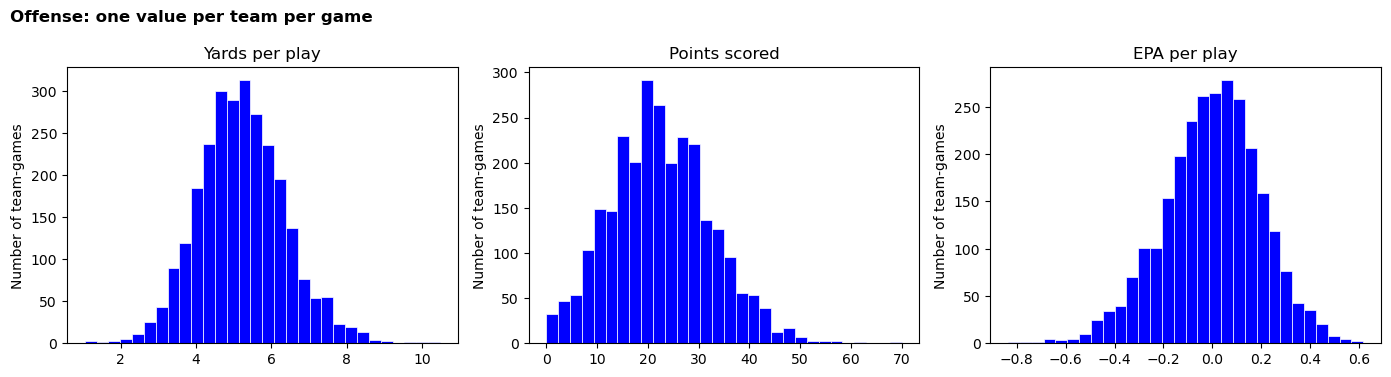

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, lab in zip(axes, ["ypp", "points", "epa_pp"], ["Yards per play", "Points scored", "EPA per play"]):
    ax.hist(team_game[col].dropna(), bins=30, color="blue", edgecolor="white", linewidth=0.5)
    ax.set_title(lab); ax.set_ylabel("Number of team-games")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.suptitle("Offense: one value per team per game", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

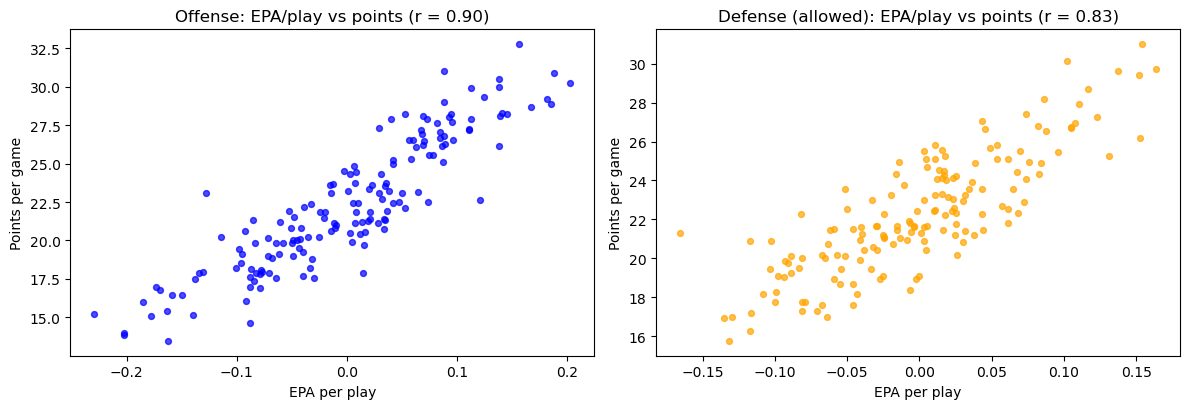

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, x, y, c, title in [(axes[0], "epa_pp", "ppg", "blue", "Offense"),
                           (axes[1], "epa_pp_allowed", "ppg_allowed", "orange", "Defense (allowed)")]:
    ax.scatter(team_season[x], team_season[y], s=18, color=c, alpha=0.7)
    r = team_season[[x, y]].corr().iloc[0, 1]
    ax.set_title(f"{title}: EPA/play vs points (r = {r:.2f})")
    ax.set_xlabel("EPA per play"); ax.set_ylabel("Points per game")
plt.tight_layout(); plt.show()

In [8]:
games = plays if INCLUDE_PLAYOFFS else plays[plays["season_type"] == "REG"]
scrim = games[(games["pass"] == 1) | (games["rush"] == 1)]

pts = pd.concat([
    games.groupby(["game_id", "posteam"])["posteam_score_post"].max().rename_axis(["game_id", "team"]),
    games.groupby(["game_id", "defteam"])["defteam_score_post"].max().rename_axis(["game_id", "team"]),
], axis=1).max(axis=1).rename("points").reset_index()

tg = (scrim.groupby(["season", "week", "game_id", "posteam"])
       .agg(plays=("play_id", "size"), yards=("yards_gained", "sum"))
       .reset_index().rename(columns={"posteam": "team"})).merge(pts, on=["game_id", "team"])
opp = tg[["game_id", "team", "points", "plays", "yards"]].rename(
    columns={"team": "opp", "points": "points_allowed", "plays": "plays_allowed", "yards": "yards_allowed"})
tg = tg.merge(opp, on="game_id").query("team != opp").sort_values(["team", "season", "week"]).reset_index(drop=True)

In [9]:
g = tg.groupby(["team", "season"])
tg["game_num"] = g.cumcount() + 1
for col in ["points", "points_allowed", "plays", "yards", "plays_allowed", "yards_allowed"]:
    tg[f"cum_{col}"] = g[col].cumsum() - tg[col]
n_prev = tg["game_num"] - 1
cur = pd.DataFrame({
    "ppg": tg.cum_points / n_prev,
    "ypp": tg.cum_yards / tg.cum_plays,
    "ppg_allowed": tg.cum_points_allowed / n_prev,
    "ypp_allowed": tg.cum_yards_allowed / tg.cum_plays_allowed,
})

In [10]:
last = (tg.groupby(["team", "season"])
        .agg(games=("game_id", "size"), points=("points", "sum"), plays=("plays", "sum"), yards=("yards", "sum"),
             points_allowed=("points_allowed", "sum"), plays_allowed=("plays_allowed", "sum"),
             yards_allowed=("yards_allowed", "sum"))
        .reset_index())
last = pd.DataFrame({
    "team": last.team, "season": last.season + 1, 
    "ppg": last.points / last.games, "ypp": last.yards / last.plays,
    "ppg_allowed": last.points_allowed / last.games, "ypp_allowed": last.yards_allowed / last.plays_allowed,
})
prev = tg[["team", "season"]].merge(last, on=["team", "season"], how="left")

w = (n_prev / n_games).clip(upper=1)
metrics = ["ppg", "ypp", "ppg_allowed", "ypp_allowed"]
for m in metrics:
    tg[m] = (w * cur[m].fillna(0) + (1 - w) * prev[m]).where(tg.game_num > 1, prev[m])

In [11]:
ref = last.groupby("season")[metrics].agg(["mean", "std"])
for m in metrics:
    mu = tg.season.map(ref[(m, "mean")]); sd = tg.season.map(ref[(m, "std")])
    tg[f"z_{m}"] = (tg[m] - mu) / sd
tg["off_score"] = (tg.z_ppg + tg.z_ypp) / 2           
tg["def_score"] = -(tg.z_ppg_allowed + tg.z_ypp_allowed) / 2
tg["first_game"] = (tg.game_num == 1).astype(int)
tg["early_game"] = tg.game_num.between(2, n_games).astype(int)

team_scores = tg.loc[tg.season > tg.season.min(),
                     ["game_id", "season", "week", "team", "game_num", "first_game", "early_game",
                      "off_score", "def_score"] + metrics].reset_index(drop=True)
print(f"team_scores: {len(team_scores):,} team-games, seasons {team_scores.season.min()}-{team_scores.season.max()}")

team_scores: 2,174 team-games, seasons 2022-2025


In [12]:
s = team_scores[["game_id", "team", "off_score", "def_score", "first_game", "early_game"]]
plays_scored = (plays[plays.season > tg.season.min()]
              .merge(s[["game_id", "team", "off_score", "first_game", "early_game"]]
                     .rename(columns={"team": "posteam", "first_game": "off_first_game", "early_game": "off_early_game"}),
                     on=["game_id", "posteam"], how="left")
              .merge(s[["game_id", "team", "def_score", "first_game", "early_game"]]
                     .rename(columns={"team": "defteam", "first_game": "def_first_game", "early_game": "def_early_game"}),
                     on=["game_id", "defteam"], how="left"))
print(f"plays_scored: {len(plays_scored):,} plays; "
      f"scores missing on {plays_scored.loc[(plays_scored['pass'] == 1) | (plays_scored['rush'] == 1), 'off_score'].isna().mean():.2%} of runs/passes")

plays_scored: 140,029 plays; scores missing on 0.00% of runs/passes


In [13]:
# Save scores data
score_cols = ["game_id", "season", "team", "off_score", "def_score", "first_game", "early_game"]
team_scores[score_cols].to_csv("data_scores.csv", index=False)